# 独立项目：Superstore 连锁超市经营分析（EDA）

> **要求：独立完成，不看任何参考答案/教程。** 遇到不会的函数自己查文档或问 AI，但分析思路和代码自己写。
> 这是一个**业务问题驱动**的项目：你不是在"画图交差"，而是在回答管理层真正关心的经营问题。

## 背景

你是一家连锁超市的数据分析师。公司在线销售 **三大类商品（家具、办公用品、科技产品）**，覆盖美国 4 大地区，拥有个人、企业、家庭办公三类客户。
现有 **2014–2017 年共 9994 条订单明细**，**每一行是"某张订单里的某一个商品"**（同一张订单含多个商品会有多行，Order ID 相同）。
管理层要你做一次全面经营体检，为下一年的产品、定价（折扣）、地区策略提供依据。

## 字段说明（数据字典）

| 列名 | 含义 |
|---|---|
| Row ID | 行编号 |
| Order ID | 订单号（一单多商品时重复） |
| Order Date | 下单日期 |
| Ship Date | 发货日期 |
| Ship Mode | 发货方式（Standard Class 标准 / Second Class 二级 / First Class 一级 / Same Day 当天） |
| Customer ID / Customer Name | 客户编号 / 姓名 |
| Segment | 客户类型：Consumer 个人、Corporate 企业、Home Office 家庭办公 |
| Country / City / State / Postal Code | 国家 / 城市 / 州 / 邮编 |
| Region | 地区：Central、East、South、West |
| Product ID / Product Name | 产品编号 / 名称 |
| Category | 大类：Furniture 家具、Office Supplies 办公用品、Technology 科技 |
| Sub-Category | 子类别（共 17 个，如 Chairs、Phones、Binders…） |
| Sales | 销售额 |
| Quantity | 销售数量 |
| Discount | 折扣率（0～0.8） |
| Profit | 利润（**负数 = 亏损**） |

## 交付规范（每个模块都要遵守）

1. 关键结果用**表格**呈现，趋势/对比用**图**呈现。
2. **每张图必须有标题 + 坐标轴含义**；图型选对（连续数值用 hist，分类对比用 bar/barh，趋势用 line，关系用 scatter）。
3. 不要 `print(绘图方法)`；不要覆盖原始列，派生内容用新列。
4. 最后结论必须是 **"发现 + 数字 + 建议动作（so what）"**，不能只写"xx 最高"。

## 模块 0：环境准备与数据加载

In [57]:
# 环境（已为你准备好，可直接运行）
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

DATA_PATH = r'C:\Users\千禧\Doubao\chats\2026-09-23\new-chat\AI学习\05_实战项目\superstore\Superstore.csv'

# TODO：自己写代码加载数据、解析日期，并完成模块1的检查
df = pd.read_csv(DATA_PATH,parse_dates=['Order Date','Ship Date'])
print(df.columns)
display(df.head())
df.info()


Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='object')


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub-Category   9994 n

---
## 模块 1：数据质量检查

**要回答：** 数据干净吗？能直接分析吗？

任务：
1. 查看行列数、每列数据类型、前几行。
2. 检查缺失值、重复行；日期是否被正确识别（不是字符串）。
3. 对发现的问题进行处理，并说明你为什么这样处理。

**交付：** 一份数据质量结论（有无问题、怎么处理的）。

In [58]:
# 模块1 在此完成
print(df.shape)
df.info()
df.head()
tmep = df.isna().sum()
print("有缺失" if tmep.any() else "无缺失")
temp = df.duplicated()
print("有重复数据" if temp.any() else "数据无重复")
print(df['Order Date'].dtype,df['Ship Date'].dtype)
#经过检测，数据内容无错误，类型无错误，无缺失，无重复，所有数据可供后续计算，操作

(9994, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub-Catego

---
## 模块 2：整体经营概况（核心 KPI）

**要回答：** 这 4 年公司整体经营得怎么样？盘子多大、赚不赚钱？

任务，计算以下核心指标：
1. 总销售额、总利润、总销售数量。
2. **总订单数**（注意：不是行数，一张订单有多行，想想怎么数不重复的 Order ID）。
3. 整体**利润率** = 总利润 / 总销售额；平均折扣率。
4. 用一句话概括整体经营状况。

**交付：** KPI 汇总表 + 一句话结论。

In [59]:
# 模块2 在此完成
print(df['Sales'].sum().__round__(2))
print(df['Profit'].sum().__round__(2))#为什么这里写成round会报错？只能写成__形式？？
print(df['Quantity'].sum())
print(df[['Sales','Profit','Quantity']].sum().round(2))#这样写又可以写成round
print(df['Order ID'].unique().__len__())#为什么这里也要加下划线啊？？？我不写就是错的
print((df['Profit'].sum().__round__(2) / df['Sales'].sum().__round__(2)).__round__(2))
#利润率为0.12，总体来说我也不知道算不算高，但是十分之一左右的利润怕是一般哦，算上其它固有的成本和人工等等消耗，我感觉总的来说就不温不火


2297200.86
286397.02
37873
Sales       2297200.86
Profit       286397.02
Quantity      37873.00
dtype: float64
5009
0.12


---
## 模块 3：产品分析（类别 → 子类别，层层下钻）

**要回答：** 钱是哪些产品赚的？哪些产品在拖后腿？

任务：
1. 三大类（Category）各自的销售额、利润、利润率、销量，用图对比。
2. 17 个子类别（Sub-Category）按利润排序，**列出所有亏损（利润为负）的子类别**。
3. 找出"**销售额很高、利润却很低甚至亏损**"（增收不增利）的子类别。
4. 思考：卖得最多的，一定最赚钱吗？

**交付：** 大类对比表+图、子类别利润排序图、亏损清单。

,Sales,Profit,Quantity,margin
Category,,,,
Furniture,741999.7953,18451.2728,8028,0.0249
Office Supplies,719047.0320,122490.8008,22906,0.1704
Technology,836154.0330,145454.9481,6939,0.1740


Sub-Category
Supplies     -1189.0995
Bookcases    -3472.5560
Tables      -17725.4811
Name: Profit, dtype: float64


<Axes: title={'center': '关于增量不增收，margin x1000000处理'}, ylabel='Sub-Category'>

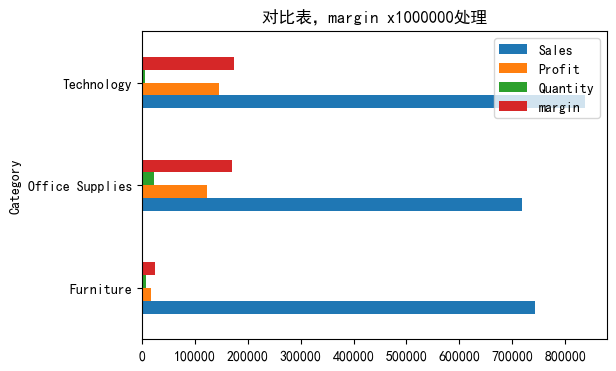

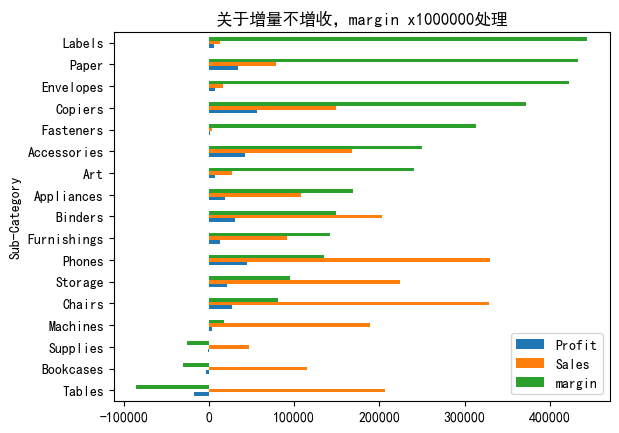

In [ ]:
# 模块3 在此完成
temp = df.groupby('Category')[['Sales','Profit','Quantity']].agg('sum')
temp['margin'] = (temp['Profit'] / temp['Sales']).round(4)
display(temp)
#考虑到这恶margin太小了，在图上没有显示，我选择使用广播放大观察
temp['margin']*=1000000
temp.plot(kind = 'barh',figsize=(6,4),title="对比表，margin x1000000处理")
temp = df.groupby('Sub-Category')['Profit'].sum()
temp = temp.sort_values(ascending=False)
print(temp[temp<0])
#增收不增利，想要通过观察什么的实现都不合理，想想就发现，其实就是利润率,这个是核心
temp = df.groupby('Sub-Category')[['Profit','Sales']].sum()
temp['margin'] = (temp['Profit'] / temp['Sales']).round(4)
temp['margin']*=1000000
temp.sort_values('margin').plot(kind = 'barh',title="关于增量不增收，margin x1000000处理")
#综上，卖的多不代表赚的多，要看利润率




---
## 模块 4：折扣与利润（问题根因定位）

**要回答：** 亏损是不是折扣造成的？折扣该不该砍？

任务：
1. 用散点图观察 Discount 和 Profit（或利润率）的关系。
2. 按折扣率分组，计算每个折扣水平下的平均利润率/平均利润，画成图。
3. 找出"折扣打到几折开始普遍亏损"。
4. 给出明确的折扣策略建议。

**交付：** 散点图 + 分折扣统计图 + 折扣建议。

,profit,sales,profitAvg,margin
Discount,,,,
0.00,320987.60,1087908.47,66.90,0.2951
0.10,9029.18,54369.35,96.06,0.1661
0.15,1418.99,27558.52,27.29,0.0515
0.20,90337.31,764594.37,24.70,0.1182
0.30,-10369.28,103226.66,-45.68,-0.1005
0.32,-2391.14,14493.46,-88.56,-0.1650
0.40,-23057.05,116417.78,-111.93,-0.1981
0.45,-2493.11,5484.97,-226.65,-0.4545
0.50,-20506.43,58918.54,-310.70,-0.3480


<Axes: title={'center': '利润率x1000000处理'}, xlabel='Discount'>

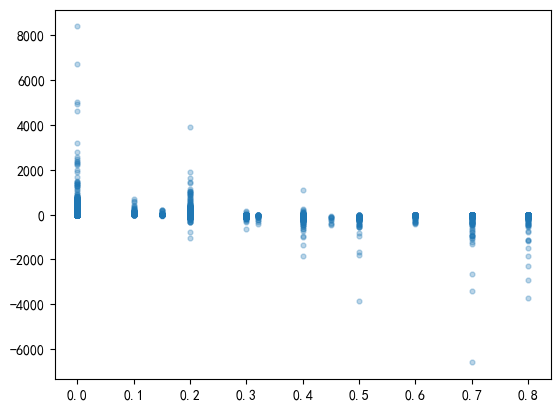

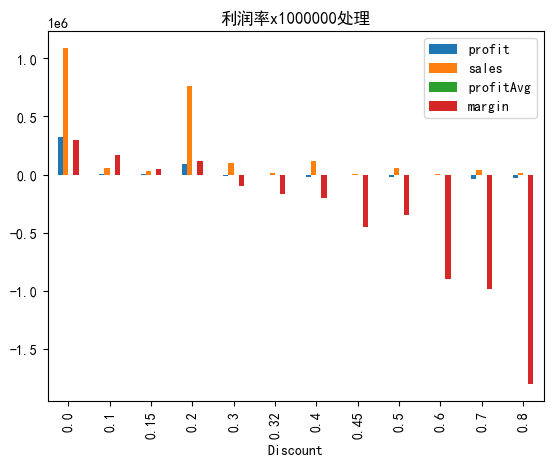

In [61]:
# 模块4 在此完成
plt.scatter(df["Discount"], df["Profit"],alpha=0.3,s=12,)
#平均利润率，我想了一下，可能有两种意思，第一种是总利润/总销售
#第二种是每一行的单独利润率的平均，但是可能会被带偏，误差大
# 总的来说，第一种应该更符合题意
df['margin'] = df['Profit']
temp = df.groupby('Discount')[['Profit','Sales']].agg(profit = ('Profit','sum'),sales = ('Sales','sum'),profitAvg = ('Profit','mean')).round(2)
temp['margin'] = (temp['profit'] / temp['sales']).round(4)
display(temp)
temp['margin']*=1000000
temp.plot(kind='bar',title='利润率x1000000处理')
#我发现如果需要图标效果直观，还是需要去配比的，我本来想通过类似配平的办法来解决
#但是发现如果最终x的数值不一样，也会导致图不直观，甚至错误？
#在这个图里，似乎只有利润率可以放大不同倍数，因为利润率是相对的
#图像结果明确，打折打到七折开始亏损（图里的0.3代表的应该是（1-折扣）得到的折扣率）
#折扣建议：原价和八折都存在严重的增量不增收的情况，合理的折扣范围应该是原价与八折之间
#同时，考虑到清理库存的情况，原价居然优于八折，神了


---
## 模块 5：地区分析

**要回答：** 哪些地区赚钱、哪些地区在失血？资源该往哪投？

任务：
1. 4 大地区的销售额、利润、利润率对比，画图。
2. 利润最高和最低的州（State）/城市（City）各是哪些。
3. 找出"销售额不低、利润却为负/很低"的问题地区。

**交付：** 地区对比表+图、Top/垫底州或城市清单。

['South' 'West' 'Central' 'East']


,Sales,Profit,margin
Region,,,
Central,501239.89,39706.36,0.0792
East,678781.24,91522.78,0.1348
South,391721.90,46749.43,0.1193
West,725457.82,108418.45,0.1494


['Kentucky' 'California' 'Florida' 'North Carolina' 'Washington' 'Texas'
 'Wisconsin' 'Utah' 'Nebraska' 'Pennsylvania' 'Illinois' 'Minnesota'
 'Michigan' 'Delaware' 'Indiana' 'New York' 'Arizona' 'Virginia'
 'Tennessee' 'Alabama' 'South Carolina' 'Oregon' 'Colorado' 'Iowa' 'Ohio'
 'Missouri' 'Oklahoma' 'New Mexico' 'Louisiana' 'Connecticut' 'New Jersey'
 'Massachusetts' 'Georgia' 'Nevada' 'Rhode Island' 'Mississippi'
 'Arkansas' 'Montana' 'New Hampshire' 'Maryland' 'District of Columbia'
 'Kansas' 'Vermont' 'Maine' 'South Dakota' 'Idaho' 'North Dakota'
 'Wyoming' 'West Virginia']
['Henderson' 'Los Angeles' 'Fort Lauderdale' 'Concord' 'Seattle'
 'Fort Worth' 'Madison' 'West Jordan' 'San Francisco' 'Fremont'
 'Philadelphia' 'Orem' 'Houston' 'Richardson' 'Naperville' 'Melbourne'
 'Eagan' 'Westland' 'Dover' 'New Albany' 'New York City' 'Troy' 'Chicago'
 'Gilbert' 'Springfield' 'Jackson' 'Memphis' 'Decatur' 'Durham' 'Columbia'
 'Rochester' 'Minneapolis' 'Portland' 'Saint Paul' 'Aurora' 'Cha

<Axes: title={'center': '利润率x1000000'}, xlabel='Region'>

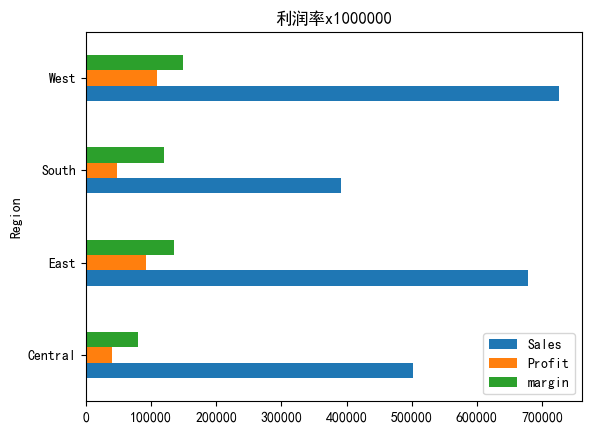

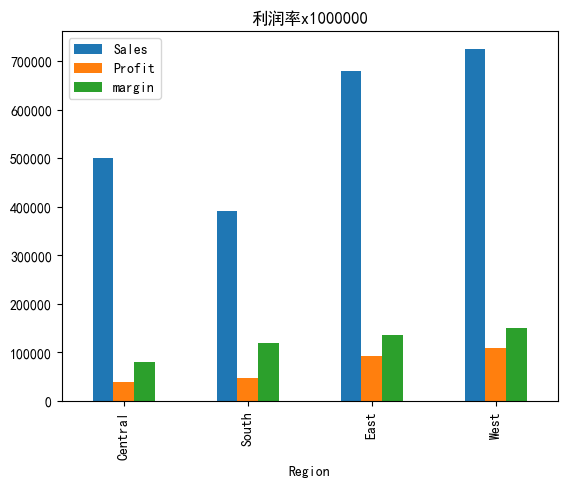

In [62]:
# 模块5 在此完成
print(df['Region'].unique())#核实地区数量
temp = df.groupby('Region')[['Sales','Profit']].sum().round(2)
temp['margin'] = (temp['Profit']/temp['Sales']).round(4)
display(temp)
temp['margin']*=1000000
temp.plot(kind='barh',title='利润率x1000000')
print(df['State'].unique())#核实州的数量
temp = df.groupby('State')['Profit'].sum()
temp = temp.sort_values(ascending=False)
#print(temp.max(),temp.min())
#我想了一下，这里不适合用maxmin，想要拿到一行数据，应该直接进行排序才是最优解
print(df['City'].unique())#核实
temp = df.groupby('City')['Profit'].sum()
temp = temp.sort_values(ascending=False)
print(temp.head(1),temp.tail(1))
#销售额不低，利润却为负数，这个属于对比问题，适合用图标解决
#但是归根结底还是看理论率，这个是核心衡量标准
temp = df.groupby('Region')[['Sales','Profit']].sum().round(2)
temp['margin'] = (temp['Profit']/temp['Sales']).round(4)
temp = temp.sort_values(by='margin')
temp['margin']*=1000000
temp.plot(kind='bar',title='利润率x1000000')
#有的地区销量不高，但与此同时利润也更低，因此衡量此项标准的还是利润率

#根据以上结论分析，虽然西部利润路最高，但是综合考量下来，南部的销售模式更健康，以更小的销售额取得了优质的利润率



---
## 模块 6：客户与发货分析

**要回答：** 哪类客户最有价值？发货方式影响利润吗？

任务：
1. 三类客户（Segment）各自的销售额、利润、利润率、订单数对比。
2. 不同发货方式（Ship Mode）的占比，以及各自的平均利润/利润率。
3. 说明应该重点维护哪类客户、哪种发货方式更划算。

**交付：** 客户对比表、发货方式占比图+利润对比。

<Axes: title={'center': '利润率x10000,平均利润x5'}, xlabel='Ship Mode'>

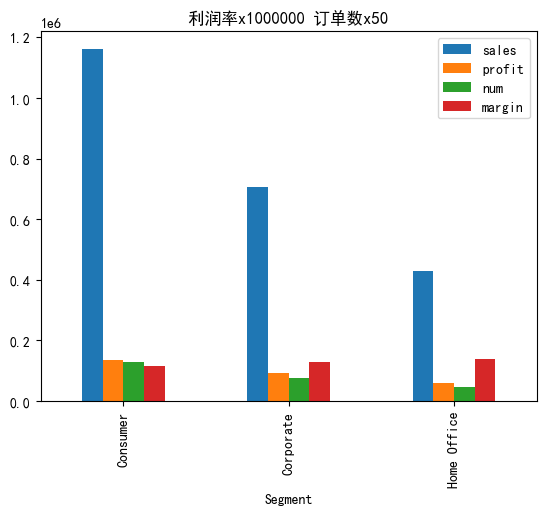

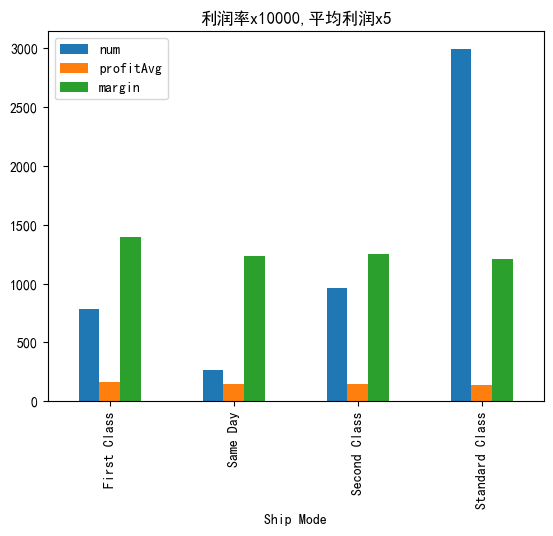

In [63]:
# 模块6 在此完成
temp = df.groupby('Segment')[['Sales','Profit','Order ID']].agg(sales = ('Sales','sum'),profit = ('Profit','sum'),num = ('Order ID','nunique')).round(2)
temp['margin'] = (temp['profit']/temp['sales']).round(4)
temp['margin']*=1000000
temp['num']*=50
temp.plot(kind='bar',title='利润率x1000000 订单数x50')
#不同发货方式的占比，有陷阱，看似是count mode ship，实则是nunique order id
temp = df.groupby('Ship Mode')[['Sales','Profit','Order ID']].agg(sales = ('Sales','sum'),profit = ('Profit','sum'),profitAvg = ('Profit','mean'),num = ('Order ID','nunique')).round(2)
numall = temp['num'].sum()
temp['proportion'] = (temp['num']/numall).round(2)
temp['margin'] = (temp['profit']/temp['sales']).round(4)
#论划算，依旧是看理论率
temp['margin']*=10000
temp['profitAvg']*=5
temp[['num','profitAvg','margin']].plot(kind='bar',title='利润率x10000,平均利润x5')

#home office用户最优质，first class的发货方式最优质




---
## 模块 7：时间趋势分析

**要回答：** 生意在增长吗？有没有季节性（旺季/淡季）？

任务：
1. 从 Order Date 提取年、月（或年月）。
2. 画出销售额、利润随时间（按月或季度）的变化趋势。
3. 判断整体是增长还是下滑，是否存在固定的旺季/淡季。
4.（选做）观察三大类各自的趋势，哪类在增长、哪类在疲软。

**交付：** 时间趋势折线图 + 趋势判断。

Sales      Profit
Order Year Order Month quarter                         
2014       1           winter    14236.8950   2450.1907
           2           winter     4519.8920    862.3084
           3           Spring    55691.0090    498.7299
           4           Spring    28295.3450   3488.8352
           5           Spring    23648.2870   2738.7096
           6           Summer    34595.1276   4976.5244
           7           Summer    33946.3930   -841.4826
           8           Summer    27909.4685   5318.1050
           9           Autumn    81777.3508   8328.0994
           10          Autumn    31453.3930   3448.2573
           11          Autumn    78628.7167   9292.1269
           12          winter    69545.6205   8983.5699
2015       1           winter    18174.0756  -3281.0070
           2           winter    11951.4110   2813.8508
           3           Spring    38726.2520   9732.0978
           4           Spring    34195.2085   4187.4962
           5           Spring    30131.6865   4667.8690
           6           Summer    24797.2920   3335.5572
           7           Summer    28765.3250   3288.6483
           8           Summer    36898.3322   5355.8084
           9           Autumn    64595.9180   8209.1627
           10          Autumn    31404.9235   2817.3660
           11          Autumn    75972.5635  12474.7884
           12          winter    74919.5212   8016.9659
2016       1           winter    18542.4910   2824.8233
           2           winter    22978.8150   5004.5795
           3           Spring    51715.8750   3611.9680
           4           Spring    38750.0390   2977.8149
           5           Spring    56987.7280   8662.1464
           6           Summer    40344.5340   4750.3781
           7           Summer    39261.9630   4432.8779
           8           Summer    31115.3743   2062.0693
           9           Autumn    73410.0249   9328.6576
           10          Autumn    59687.7450  16243.1425
           11          Autumn    79411.9658   4011.4075
           12          winter    96999.0430  17885.3093
2017       1           winter    43971.3740   7140.4391
           2           winter    20301.1334   1613.8720
           3           Spring    58872.3528  14751.8915
           4           Spring    36521.5361    933.2900
           5           Spring    44261.1102   6342.5828
           6           Summer    52981.7257   8223.3357
           7           Summer    45264.4160   6952.6212
           8           Summer    63120.8880   9040.9557
           9           Autumn    87866.6520  10991.5556
           10          Autumn    77776.9232   9275.2755
           11          Autumn   118447.8250   9690.1037
           12          winter    83829.3188   8483.3468

,Sales,Profit
quarter,,
Autumn,860434.0014,104109.9431
Spring,497796.4291,62593.4313
Summer,459000.8393,56895.3986
winter,479969.5905,62798.2487


<Axes: ylabel='quarter'>

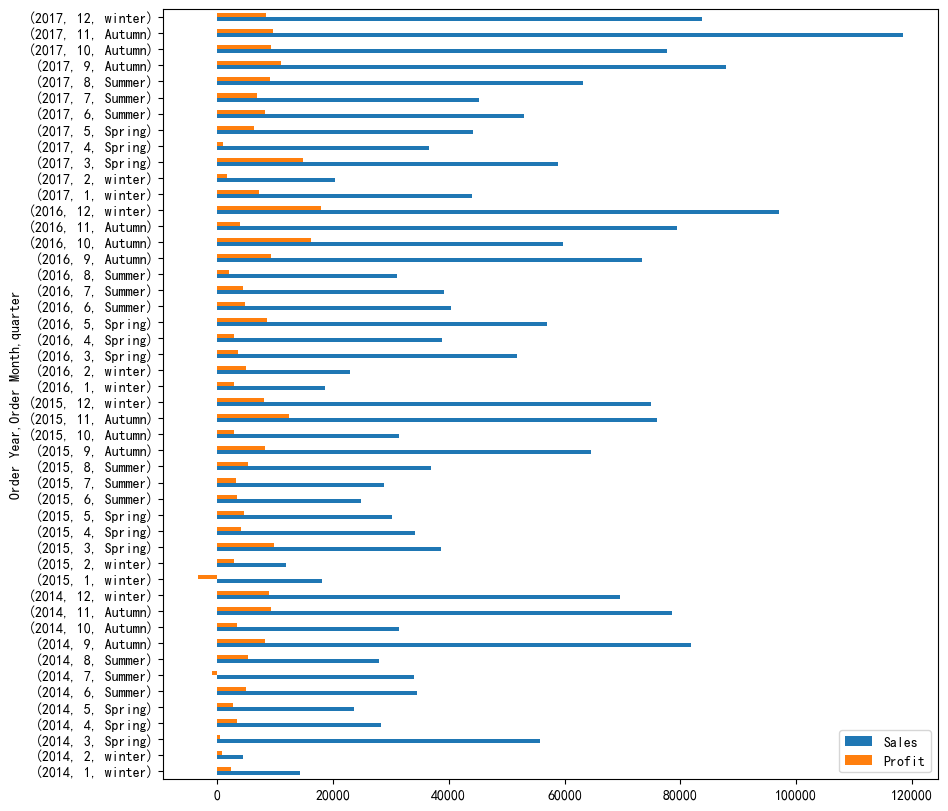

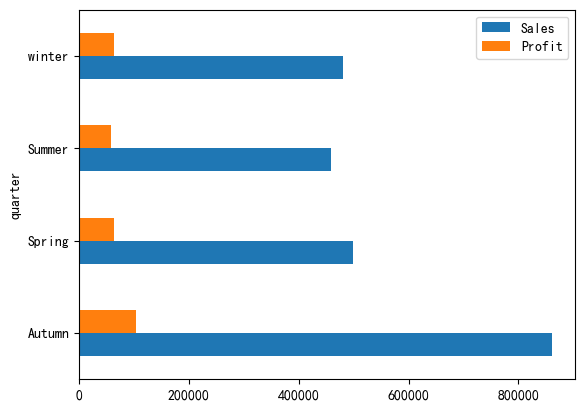

In [ ]:
# 模块7 在此完成
temp = df
temp['Order Year'] = temp['Order Date'].dt.year
temp['Order Month'] = temp['Order Date'].dt.month
conds = [
    temp['Order Month'].isin([3,4,5]),
    temp['Order Month'].isin([6,7,8]),
    temp['Order Month'].isin([9,10,11]),
    temp['Order Month'].isin([12,1,2]),
]
choices = ['Spring','Summer','Autumn','winter']
temp['quarter'] = np.select(conds,choices,default='Unknown')
temp1 = temp.groupby(['Order Year','Order Month','quarter'])[['Sales','Profit']].sum()
#按月
display(temp1)
temp1.plot(kind='barh',figsize=(10,10))
#按季度，需要重新添加季度标签列
temp2 = temp.groupby('quarter')[['Sales','Profit']].sum()
display(temp2)
temp2.plot(kind='barh')

#结果显而易见，生意并未出现明显增长，而是处于较为稳定的月份规律中，其中秋季为旺季，其余三个季节相对均衡，属于正常销售季


---
## 模块 8：最终结论与行动建议

**要回答：** 如果你是向 CEO 汇报，你会让公司做哪几件事？

任务：写 **6 条结论**，结构如下：
- **做得好的（2条）**：哪些业务/地区/客户是亮点。
- **存在问题的（2条）**：哪些产品/折扣/地区在亏钱，根因是什么。
- **具体行动建议（2条）**：下一步该做什么、停什么、加投什么。

每条必须带**具体数字**，并写清"**所以应该怎么做**"。
禁止只写"xx 最高 / xx 最低"这种没有行动价值的结论。

**交付：** 6 条可直接汇报的结论。

In [ ]:
# 模块8 在此完成

#我不打算写这个板块，我觉得整理的能力和遇到对应情况能够处理数据的能力基础需要用，但是不必花费心思，ai现在可以处理的环境太多了，我只是为了能够看懂，能够处理，为后面的学习铺路，其余的，我觉得可以交给ai分析，效果绝对比人为分析优质，人最重要的应该是决策能力


---
## 完成后自查清单

- [ ] 订单数是按**不重复 Order ID** 数的，不是行数。
- [ ] 利润率 = 利润 / 销售额，且区分了"整体 / 各类 / 各地区"。
- [ ] 找到了**亏损子类别**和"增收不增利"的产品。
- [ ] 说清了**折扣与亏损的关系**，给出折扣门槛建议。
- [ ] 每张图都有标题和坐标轴，中文不乱码，图型选对。
- [ ] 没有覆盖原始数据列；没有 print 绘图对象。
- [ ] 最终 6 条结论都有数字 + 建议，能直接给非技术的管理层看。

> 全部完成后，把它整理成你的第二个简历项目："基于 Superstore 的连锁超市经营分析"，写清分析框架、关键发现和建议。